# 🛠️ Pipeline Hợp nhất, Làm sạch & Gộp Dữ liệu Khách hàng Olist
**Dự án:** Xây dựng mô hình phân khúc khách hàng thương mại điện tử Olist  
**Nhiệm vụ:** A03 (Hợp nhất các bảng), A04 (Làm sạch dữ liệu), A05 (Gộp về cấp `customer_unique_id`)  
**Phụ trách chính:** Thành viên A (Trưởng nhóm / Kỹ sư dữ liệu & Mô hình hóa)  
**Sản phẩm bàn giao cốt lõi:** `data/processed/olist_clean.parquet` dùng làm đầu vào thống nhất cho cả nhóm (Bàn giao cho Thành viên B & C)  

---

### Mục tiêu của Notebook:
1. **Hợp nhất dữ liệu (A03):** Kết nối 7 bảng dữ liệu Olist (`orders`, `customers`, `order_items`, `products`, `translation`, `order_payments`, `order_reviews`) giải quyết triệt để quan hệ 1-nhiều (1 đơn có nhiều sản phẩm, nhiều khoản thanh toán).
2. **Làm sạch dữ liệu (A04):** Lọc đơn `delivered`, chuẩn hóa mốc thời gian, loại bỏ các ngoại lệ thời gian giao hàng bất hợp lý, xử lý giá trị khuyết thiếu.
3. **Gộp về cấp khách hàng duy nhất (A05):** Tổng hợp dữ liệu theo `customer_unique_id` (không dùng `customer_id`), tạo ra bộ đặc trưng toàn diện bao gồm:
   - **Nhóm Loyalty & RFM:** `recency`, `frequency`, `monetary`, `avg_order_value`, `max_order_value`.
   - **Nhóm Vận chuyển & Giao hàng:** `total_freight`, `avg_freight_value`, `freight_ratio`, `avg_delivery_duration_days`, `delayed_order_ratio`.
   - **Nhóm Đánh giá & Trải nghiệm:** `avg_review_score`, `low_review_ratio`, `has_comment_ratio`.
   - **Nhóm Thanh toán & Hành vi:** `primary_payment_type`, `max_payment_installments`, `voucher_payment_ratio`, `unique_categories_count`.
4. **Xuất file chuẩn hóa:** Lưu tập dữ liệu sạch dưới định dạng `olist_clean.parquet` với hiệu năng nén cao và giữ nguyên schema dữ liệu.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Thêm thư mục gốc vào sys.path để import module từ src
PROJECT_ROOT = Path("..").resolve() if Path("..").resolve().name == "ktdl" else Path(".").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_pipeline import load_raw_data, clean_orders_and_items, aggregate_to_customer_level, run_pipeline

pd.set_option('display.max_columns', 35)
pd.set_option('display.float_format', lambda x: '%.2f' % x)
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 5)

print("✅ Đã kết nối thành công với module src.data_pipeline!")

✅ Đã kết nối thành công với module src.data_pipeline!


## 2. Thực thi Pipeline Làm sạch & Hợp nhất Dữ liệu

In [2]:
# Chạy trọn vẹn pipeline và xuất ra olist_clean.parquet
raw_path = PROJECT_ROOT / "data" / "raw"
output_path = PROJECT_ROOT / "data" / "processed" / "olist_clean.parquet"

df_customers_clean = run_pipeline(
    raw_dir=str(raw_path),
    output_parquet=str(output_path)
)

[1/6] Dang nap cac bang du lieu goc...


[+] Da nap thanh cong 7 bang du lieu.
[2/6] Loc don hang hop le & chuyen doi thoi gian...
[3/6] Tong hop du lieu mat hang (order_items) & san pham...


[4/6] Tong hop du lieu thanh toan & danh gia...


[5/6] Ghep noi (Join) tat ca ve cap don hang...
[+] Hoan tat hop nhat cap don hang: 96,470 don hop le.
[6/6] Nhom theo customer_unique_id va trich xuat dac trung...
    Ngay moc Recency: 2018-08-30


[+] Hoan tat gop ve cap khach hang! Tong so khach duy nhat: 93,350


[+] Da xuat file Parquet thanh cong tai: C:\Users\Admin\Downloads\ktdl\data\processed\olist_clean.parquet


## 3. Kiểm tra Tính toàn vẹn và Phân phối của Bộ Dữ liệu Chuẩn hóa

In [3]:
print(f"📊 Kích thước bảng khách hàng sạch: {df_customers_clean.shape[0]:,} dòng x {df_customers_clean.shape[1]} cột")
print(f"🔑 Số khách hàng duy nhất (customer_unique_id): {df_customers_clean['customer_unique_id'].nunique():,}")
print(f"❌ Số giá trị thiếu (Null) còn lại: {df_customers_clean.isnull().sum().sum()}")

# Hiển thị 5 dòng đầu tiên
display(df_customers_clean.head())

📊 Kích thước bảng khách hàng sạch: 93,350 dòng x 29 cột
🔑 Số khách hàng duy nhất (customer_unique_id): 93,350
❌ Số giá trị thiếu (Null) còn lại: 0


,customer_unique_id,customer_state,customer_city,first_purchase_date,last_purchase_date,recency,frequency,monetary,avg_order_value,max_order_value,total_items,avg_items_per_order,total_freight,avg_freight_value,freight_ratio,avg_delivery_duration_days,avg_delay_days,delayed_order_count,delayed_order_ratio,avg_review_score,low_review_ratio,has_comment_ratio,primary_payment_type,max_payment_installments,avg_payment_installments,voucher_used_count,voucher_payment_ratio,unique_categories_count,favorite_category
0,0000366f3b9a7992bf8c76cfdf3221e2,SP,cajamar,2018-05-10 10:56:27,2018-05-10 10:56:27,112,1,141.90,141.90,141.90,1,1.00,12.00,12.00,0.08,6.41,-4.13,0,0.00,5.00,0.00,1.00,credit_card,8.00,8.00,0.00,0.00,1,bed_bath_table
1,0000b849f77a49e4a4ce2b2a4ca5be3f,SP,osasco,2018-05-07 11:11:27,2018-05-07 11:11:27,115,1,27.19,27.19,27.19,1,1.00,8.29,8.29,0.30,3.29,-4.25,0,0.00,4.00,0.00,0.00,credit_card,1.00,1.00,0.00,0.00,1,health_beauty
2,0000f46a3911fa3c0805444483337064,SC,sao jose,2017-03-10 21:05:03,2017-03-10 21:05:03,537,1,86.22,86.22,86.22,1,1.00,17.22,17.22,0.20,25.73,-1.39,0,0.00,3.00,0.00,0.00,credit_card,8.00,8.00,0.00,0.00,1,stationery
3,0000f6ccb0745a6a4b88665a16c9f078,PA,belem,2017-10-12 20:29:41,2017-10-12 20:29:41,321,1,43.62,43.62,43.62,1,1.00,17.63,17.63,0.40,20.04,-11.11,0,0.00,4.00,0.00,1.00,credit_card,4.00,4.00,0.00,0.00,1,telephony
4,0004aac84e0df4da2b147fca70cf8255,SP,sorocaba,2017-11-14 19:45:42,2017-11-14 19:45:42,288,1,196.89,196.89,196.89,1,1.00,16.89,16.89,0.09,13.14,-7.04,0,0.00,5.00,0.00,0.00,credit_card,6.00,6.00,0.00,0.00,1,telephony


In [4]:
# Thống kê mô tả các đặc trưng số quan trọng
key_numeric_cols = [
    'recency', 'frequency', 'monetary', 'avg_order_value',
    'freight_ratio', 'avg_delivery_duration_days', 'avg_delay_days',
    'avg_review_score', 'max_payment_installments'
]

display(df_customers_clean[key_numeric_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
recency,93350.00,237.95,152.59,1.00,114.00,219.00,346.00,714.00
frequency,93350.00,1.03,0.21,1.00,1.00,1.00,1.00,15.00
monetary,93350.00,165.17,226.30,9.59,63.01,107.78,182.50,13664.08
avg_order_value,93350.00,160.29,219.56,9.59,62.33,105.62,176.56,13664.08
freight_ratio,93350.00,0.21,0.12,0.00,0.12,0.18,0.27,0.96
avg_delivery_duration_days,93350.00,12.57,9.55,0.53,6.79,10.23,15.72,209.63
avg_delay_days,93350.00,-11.15,10.14,-146.02,-16.23,-11.75,-6.39,188.98
avg_review_score,93350.00,4.16,1.28,1.00,4.00,5.00,5.00,5.00
max_payment_installments,93350.00,2.94,2.72,0.00,1.00,2.00,4.00,24.00


## 4. Trực quan hóa Phân phối Đặc trưng Cốt lõi

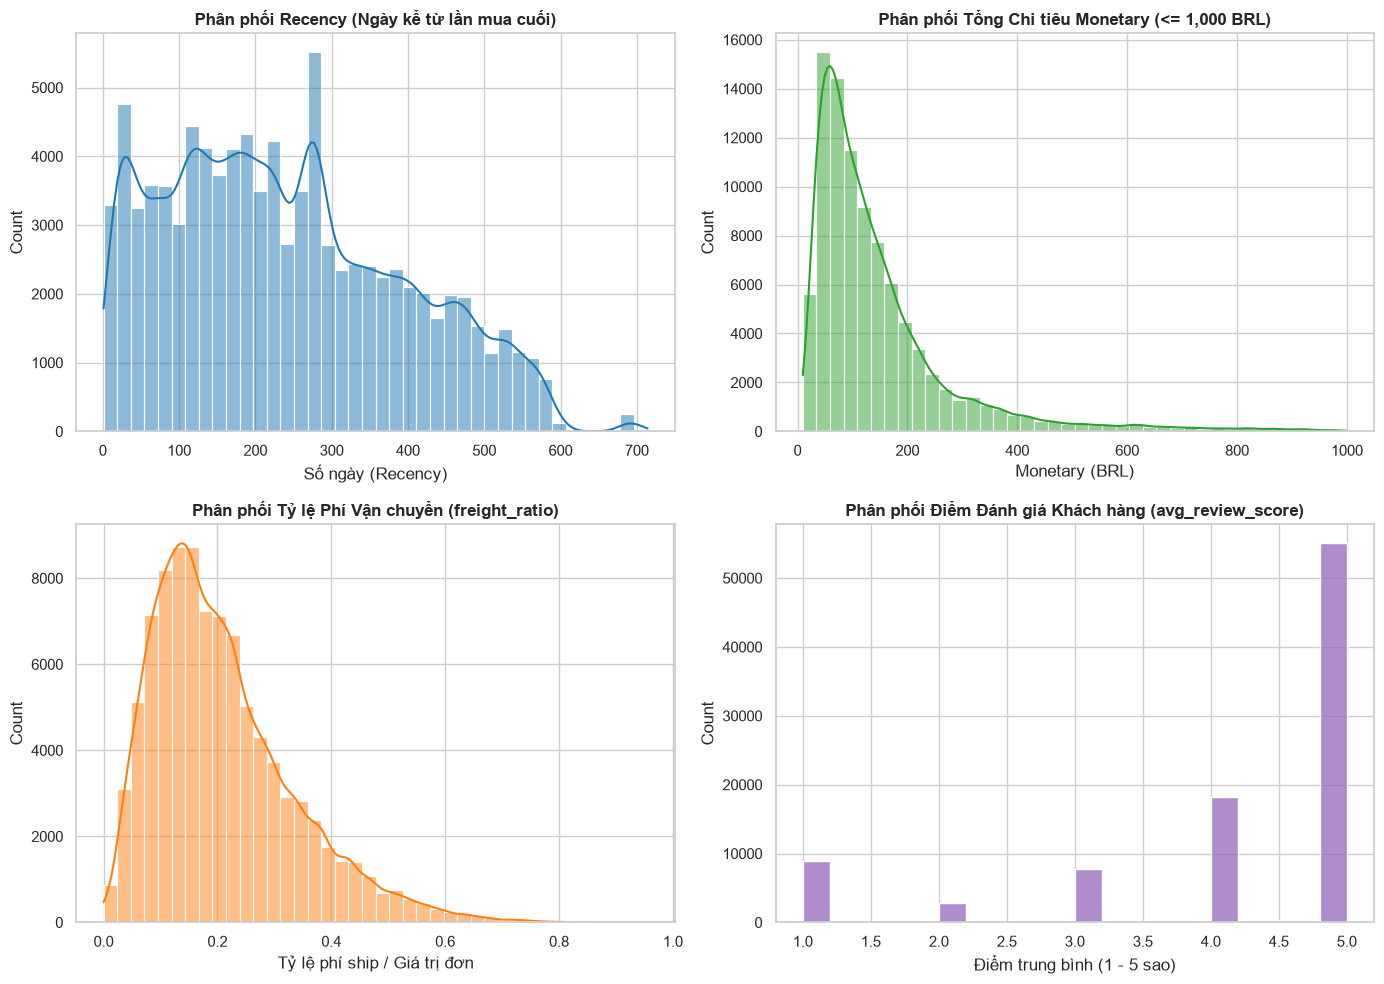

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Phân phối Recency (Số ngày mua hàng gần nhất)
sns.histplot(df_customers_clean['recency'], bins=40, kde=True, ax=axes[0, 0], color='#1f77b4')
axes[0, 0].set_title("Phân phối Recency (Ngày kể từ lần mua cuối)", fontweight='bold')
axes[0, 0].set_xlabel("Số ngày (Recency)")

# 2. Phân phối Chi tiêu Monetary (dưới 1,000 BRL để quan sát rõ)
sns.histplot(df_customers_clean[df_customers_clean['monetary'] <= 1000]['monetary'], bins=40, kde=True, ax=axes[0, 1], color='#2ca02c')
axes[0, 1].set_title("Phân phối Tổng Chi tiêu Monetary (<= 1,000 BRL)", fontweight='bold')
axes[0, 1].set_xlabel("Monetary (BRL)")

# 3. Phân phối Tỷ lệ Phí Vận chuyển (freight_ratio)
sns.histplot(df_customers_clean['freight_ratio'], bins=40, kde=True, ax=axes[1, 0], color='#ff7f0e')
axes[1, 0].set_title("Phân phối Tỷ lệ Phí Vận chuyển (freight_ratio)", fontweight='bold')
axes[1, 0].set_xlabel("Tỷ lệ phí ship / Giá trị đơn")

# 4. Phân phối Điểm Đánh giá Trung bình (avg_review_score)
sns.histplot(df_customers_clean['avg_review_score'], bins=20, ax=axes[1, 1], color='#9467bd')
axes[1, 1].set_title("Phân phối Điểm Đánh giá Khách hàng (avg_review_score)", fontweight='bold')
axes[1, 1].set_xlabel("Điểm trung bình (1 - 5 sao)")

plt.tight_layout()
plt.show()

## 5. Bàn giao & Kế hoạch Tiếp theo (Handover Plan)

Bộ dữ liệu `data/processed/olist_clean.parquet` chính thức được hoàn thiện và đóng gói:

| Thành viên | Nhiệm vụ nhận bàn giao | Nội dung cần làm tiếp theo |
| :--- | :--- | :--- |
| **Thành viên B** | B06, B07 - B12 | Sử dụng các cột `freight_ratio`, `avg_delivery_duration_days`, `avg_delay_days`, `avg_review_score`, `low_review_ratio` để phân tích ngưỡng dịch vụ và đào sâu quan hệ giữa giao trễ và phàn nàn. |
| **Thành viên C** | C05, C08 | Sử dụng các cột `recency`, `frequency`, `monetary`, `avg_order_value`, `primary_payment_type` để xây dựng phân khúc RFM đối chiếu với bộ dữ liệu Online Retail II. |
| **Thành viên A** | A06, A07, A08 | Tiến hành tiền xử lý đặc trưng (log transform biến lệch, chuẩn hóa `StandardScaler`) và thử nghiệm các mô hình phân cụm K-Means, GMM, DBSCAN. |

---
*Notebook được biên soạn tự động phục vụ đồ án KTDL Olist.*